In [15]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

#changes default of autoreloader to continually reload (2) rather than only on restart
%load_ext autoreload
%autoreload 2

import os
import glob


desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
mypath = desktop
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc
from Summary_analysis import summary_data
from plots import plot_dsc, cummulative_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


import data

In [2]:
from pathlib import Path
path_to_data='//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/'

STEDdata = {}
for file in glob.glob(path_to_data+"*Local*"):
    print(file)
    name = Path(file).name
    dendrite = 'dendrite'+name.split(' - ')[0]
    
    STEDdata[dendrite] = {'path':path_to_data} 
    STEDdata[dendrite]['file']= name
    STEDdata[dendrite]['ex_factor'] = 1
    STEDdata[dendrite]['res'] = 0.04



//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\14 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\20 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\25-1 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\26 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\26-1 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\41-2 - Local Diameter.csv
//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables\42-2 - Local Diameter.csv


analyse frames in data dic

In [3]:
frames = [STEDdata]
for data in frames:
    for name, path in tqdm(data.items()): 
        print(data[name]['path'])
        file_path = data[name]['path']+data[name]['file']
        data[name] = branch_dsc(file_path, data[name]['res'], data[name]['ex_factor'])


  0%|          | 0/7 [00:00<?, ?it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 14%|█▍        | 1/7 [00:00<00:01,  3.10it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 29%|██▊       | 2/7 [00:00<00:01,  2.59it/s]

...

 71%|███████▏  | 5/7 [00:01<00:00,  3.78it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


 86%|████████▌ | 6/7 [00:01<00:00,  3.82it/s]

//10.10.20.24/messdaten/Tony/Bonn/Data/Distal_Dendrite/Morphology/STED/michelle/140413_5weeks_thy1_dg/tables/


100%|██████████| 7/7 [00:01<00:00,  3.57it/s]


plot the individual dendrites with each DSC highlited in a different colour

In [ ]:
plot_dsc(STEDdata)

get summary stats

In [ ]:
fig, ax = cummulative_plot(STEDdata)

ax.set_xlim([0,1000])

#fig.savefig('C:/Users/Tony Kelly/Desktop/DSC_Cumulative.eps', bbox_inches = 'tight')

get mean of all DSCs across all dendrites

c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\anaconda3\Lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
c:\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
c:\anaconda3\Lib\site-packages\seaborn\categorical.py:166: FutureWarning: Setting a gradient palette using color= is deprecated and will be removed in version 0.13. Set `palette='dark:lightgrey'` for same effect.
  warnings

(0.0, 800.0)

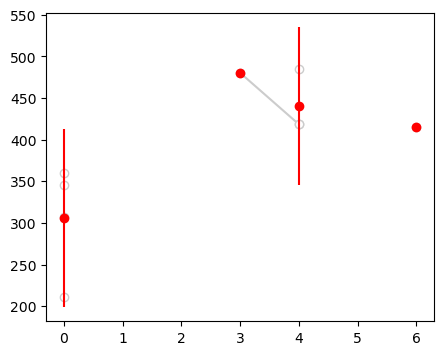

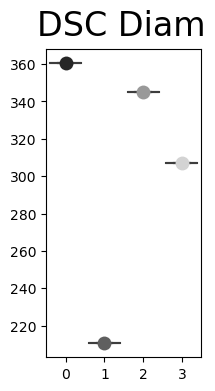

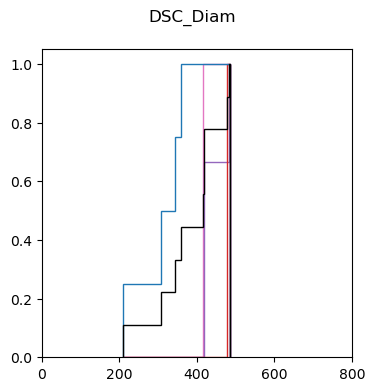

In [20]:
df= summary_data(STEDdata, 'mean')

fig, ax = plt.subplots(figsize=(2, 4))
fig.suptitle('DSC Diam', fontsize=24)
ax=sns.boxplot(data=df.dropna(), showfliers=False)
ax=sns.stripplot(data=df.dropna(), size=10, color='lightgrey')


fig, ax = plt.subplots(figsize=(4, 4))
n_bins=200
fig.suptitle("DSC_Diam")
# plot the cumulative histogra
n, bins, patches = ax.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='black', density=True, histtype='step', cumulative=True)
ax.set_xlim([0,800])